# GraspGenX on objects it has never seen

GraspGenX generates 6-DOF grasps for *any* gripper, including grippers it was not trained on.
Here we ask a narrower question:

**Does it still work on objects that were not in its training or validation set?**

The model was trained on Objaverse meshes. We test it on **10 YCB objects** — a separate,
real-scanned household-object benchmark — using **our own fin-ray gripper**, described only by
its swept-volume numbers.

Everything runs on the Mac CPU, about 2 seconds per object.

## 1. Setup

In [1]:
import json, os, pathlib, time
import numpy as np, trimesh, matplotlib.pyplot as plt

os.environ["GRASPGENX_DEVICE"] = "cpu"   # MPS gives wrong numbers for this model

from graspgenx import get_checkpoints_version_dir
from graspgenx.grasp_server import GraspGenXSampler
from graspgenx.utils.checkpoint_io import load_model_cfg
from graspgenx.x_grippers import make_sweep_volume_gripper_info

ROOT = pathlib.Path.cwd()
YCB  = ROOT/"data"/"ycb"
OUT  = ROOT/"stage2_grasp"/"results"; OUT.mkdir(exist_ok=True)

OBJECTS = ["002_master_chef_can", "005_tomato_soup_can", "006_mustard_bottle",
           "011_banana", "021_bleach_cleanser", "025_mug", "035_power_drill",
           "037_scissors", "048_hammer", "055_baseball"]
print(len(OBJECTS), "objects")

2026-09-11 09:22:32,217 - OpenGL.acceleratesupport - INFO - OpenGL_accelerate module loaded


2026-09-11 09:22:32,241 - OpenGL.arrays.arraydatatype - INFO - Using accelerated ArrayDatatype


2026-09-11 09:22:32,407 - graspgenx.dataset.dataset - WARNING - Could not import renderer (pyrender): dlsym(0x330bff124, class_getMethodImplementation_stret): symbol not found. Rendering functions will be unavailable (OK for training).


/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/pointnet/pointnet2_utils.py:23: UserWarning: Unable to load pointnet2_ops cpp extension. JIT Compiling.
  warnings.warn("Unable to load pointnet2_ops cpp extension. JIT Compiling.")
/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/pointnet/pointnet2_utils.py:40: UserWarning: Unable to import PointNet++ backbone (pointnet2_ops). PointNet++ models will not be available. Other backbones (e.g. WarpConvNet) are unaffected.
  warnings.warn(


10 objects


The meshes come from the YCB benchmark. This downloads them once (~140 MB).

In [2]:
import subprocess

BASE = "http://ycb-benchmarks.s3-website-us-east-1.amazonaws.com/data/google"
for name in OBJECTS:
    if (YCB/name).exists():
        continue
    YCB.mkdir(parents=True, exist_ok=True)
    tgz = YCB/f"{name}.tgz"
    subprocess.run(["curl", "-sfL", f"{BASE}/{name}_google_16k.tgz", "-o", str(tgz)], check=True)
    subprocess.run(["tar", "xzf", str(tgz), "-C", str(YCB)], check=True)
    tgz.unlink()
    print("downloaded", name)

print("meshes ready:", len(list(YCB.glob("*/google_16k/nontextured.ply"))))

meshes ready: 26


## 2. Are these objects really unseen?

GraspGenX's splits list Objaverse assets by UUID. YCB objects are scans of real products from a
different dataset, so they cannot appear in those lists. We check it rather than assume it.

In [3]:
seen = set()
for f in (ROOT/"data"/"objaverse"/"splits").glob("*/valid.txt"):
    seen |= {l.strip() for l in open(f) if l.strip()}

print(f"{len(seen)} object ids in the GraspGen splits, e.g. {list(seen)[0]}")
print("overlap with our YCB objects:", seen & set(OBJECTS))

1224 object ids in the GraspGen splits, e.g. 4a76b1f3c15e41d39267bf22782ab6af
overlap with our YCB objects: set()


## 3. Our gripper

GraspGenX does not read a mesh or a URDF. It conditions on **12 numbers**: the box the fingers
sweep out when open, and the same box half-closed. We measured ours from the printed STLs.

In [4]:
params = json.load(open(ROOT/"data"/"gripper"/"params_legacy.json"))
g = params["grippers"]["2-finger"]

gripper = make_sweep_volume_gripper_info(
    g["extents_open"], g["offset_open"],
    g["extents_mid"],  g["offset_mid"],
    name="finray_2f",
)
print("aperture   ", g["extents_open"][0]*1000, "mm")
print("finger reach", g["extents_open"][2]*1000, "mm")

aperture    148.10000000000002 mm
finger reach 38.3 mm


## 4. Load the model

In [5]:
ckpt = get_checkpoints_version_dir()
cfg  = load_model_cfg(str(ckpt/"gen"), str(ckpt/"dis"))
sampler = GraspGenXSampler(cfg, gripper_info=gripper)
print("ready")

Generator checkpoint : /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth
Discriminator checkpoint: /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth
Generator      : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=512, pointnet_ver=v2
  DDPM         : train_steps=20, eval_steps=20, beta_schedule=squaredcos_cap_v2, clip_sample=True, compositional=True
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp
Discriminator  : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=256, pointnet_ver=v2
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp


/opt/anaconda3/envs/graspgenx/lib/python3.12/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


2026-09-11 09:22:34,742 - graspgenx.models.discriminator - INFO - Pose representation is mlp


2026-09-11 09:22:34,745 - graspgenx.models.grasp_gen - INFO - Loading generator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth


2026-09-11 09:22:35,748 - graspgenx.models.grasp_gen - INFO - Loading discriminator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth


ready


## 5. Run inference

For each object: sample 3500 points off the mesh surface, centre them, and ask for grasps.
The sampler runs two passes and returns the 20 best from each, so 40 grasps per object.

In [6]:
def grasps_for(name, n_keep=20):
    mesh = trimesh.load(YCB/name/"google_16k"/"nontextured.ply", force="mesh")
    pts, _ = trimesh.sample.sample_surface(mesh, 3500)
    pts = np.asarray(pts, dtype=np.float32)
    centre = pts.mean(0)
    pts -= centre                           # the model expects a centred cloud
    mesh.apply_translation(-centre)         # keep the mesh in the same frame

    poses, conf = GraspGenXSampler.run_inference(
        pts, sampler, grasp_threshold=-1.0, num_grasps=200,
        topk_num_grasps=n_keep, remove_outliers=False,
    )
    return pts, poses.cpu().numpy(), conf.cpu().numpy(), mesh


results = {}
for name in OBJECTS:
    t = time.time()
    pts, poses, conf, mesh = grasps_for(name)
    results[name] = dict(pts=pts, poses=poses, conf=conf, mesh=mesh,
                         size=mesh.extents*1000)
    print(f"{name:22s} {len(poses):3d} grasps   "
          f"confidence {conf.min():.2f}-{conf.max():.2f}   {time.time()-t:.1f}s")

/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/generator.py:853: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.sqrt(torch.tensor(var_pos, device=device)),
/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/generator.py:865: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.sqrt(torch.tensor(var_rot, device=device)),


2026-09-11 09:22:37,405 - graspgenx.grasp_server - INFO - Confidences min: 0.02130, max: 0.84078


2026-09-11 09:22:37,405 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:22:37,407 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 1, total grasps: 20


2026-09-11 09:22:37,408 - graspgenx.grasp_server - INFO - Time taken for inference: 1.2092506885528564 seconds


...

2026-09-11 09:22:57,005 - graspgenx.grasp_server - INFO - Confidences min: 0.00071, max: 0.89419


2026-09-11 09:22:57,005 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:22:57,007 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-11 09:22:57,007 - graspgenx.grasp_server - INFO - Time taken for inference: 0.9801881313323975 seconds


055_baseball            40 grasps   confidence 0.80-0.90   2.2s


## 6. Collage

Grey dots are the object. Each fork is one predicted grasp, drawn with our gripper's control
points — the two prongs are where the fingers close, and the stem runs back to the gripper base.
Blue is the highest-confidence grasp, orange the next two.

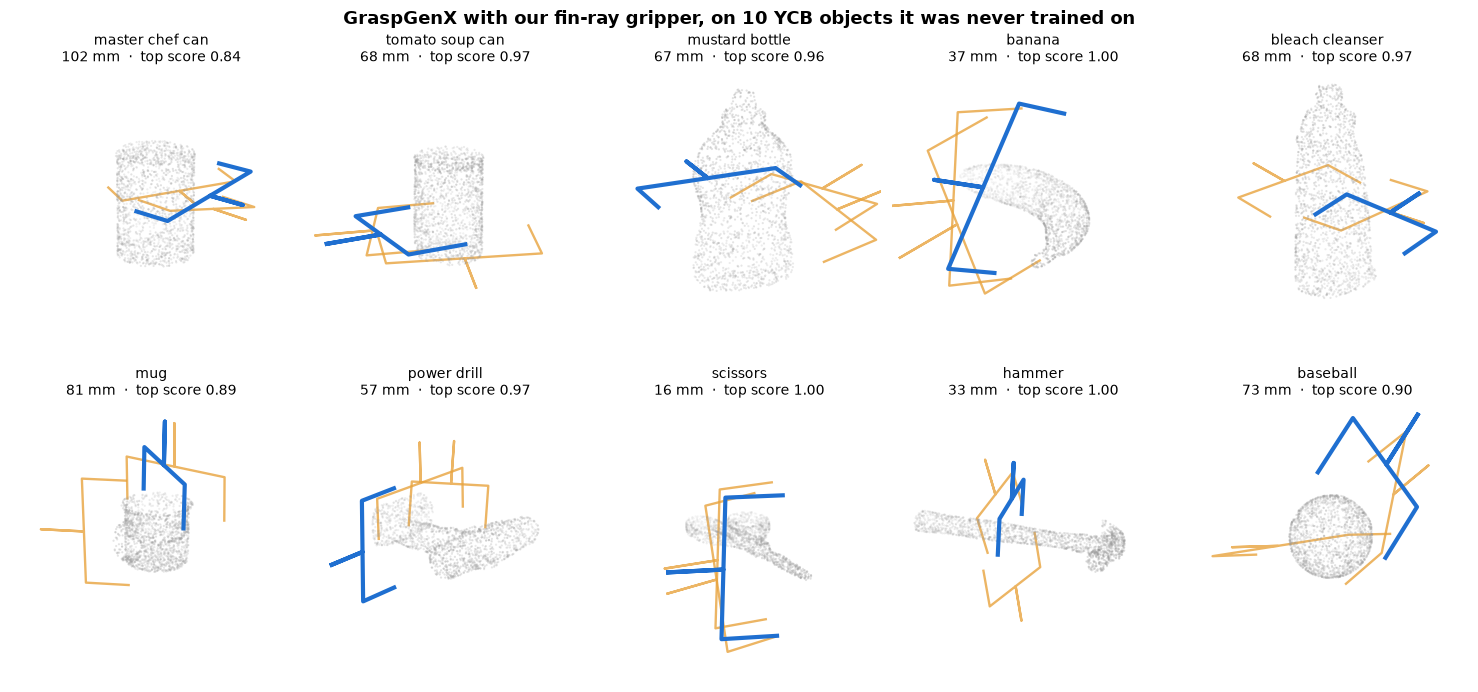

In [7]:
def fork(pose):
    """The gripper outline (7 points) placed at one grasp pose."""
    pts = np.array(gripper.control_points_visualization[0], dtype=float)
    return (pose @ pts.T).T[:, :3]


fig = plt.figure(figsize=(15, 7.0))
for i, name in enumerate(OBJECTS):
    r = results[name]
    top3 = np.argsort(-r["conf"])[:3]

    ax = fig.add_subplot(2, 5, i+1, projection="3d")
    ax.scatter(*r["pts"][::2].T, s=2.5, c="0.6", alpha=.55, linewidths=0)
    for rank, k in enumerate(reversed(top3)):
        best = rank == len(top3)-1
        ax.plot(*fork(r["poses"][k]).T, color="#1f6fd0" if best else "#e8a33d",
                lw=3.0 if best else 1.7, alpha=1.0 if best else .8,
                zorder=3 if best else 2)

    # frame both the object and the winning gripper pose
    lim = max(np.abs(r["pts"]).max(), np.abs(fork(r["poses"][top3[0]])).max())
    for setter in (ax.set_xlim, ax.set_ylim, ax.set_zlim): setter(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=1.5)
    ax.view_init(elev=20, azim=45); ax.set_axis_off()
    ax.set_title(f"{name[4:].replace('_',' ')}\n"
                 f"{r['size'].min():.0f} mm  ·  top score {r['conf'].max():.2f}",
                 fontsize=10, pad=-4)

fig.suptitle("GraspGenX with our fin-ray gripper, on 10 YCB objects it was never trained on",
             fontsize=13, fontweight="bold", y=.98)
fig.subplots_adjust(top=.90, bottom=.02, left=.01, right=.99, wspace=0, hspace=.18)
fig.savefig(OUT/"graspgenx_unseen_objects.png", dpi=150, facecolor="white")
plt.show()

## 7. Sanity check against a gripper GraspGenX already knows

A confidence of 0.99 is the model's own opinion. For an independent number: the sweep volume says
where the object should sit once the fingers close. We transform that point by each grasp pose and
measure how far it lands from the object surface.

On its own that number means little, so we run the same objects again with **franka_panda** — a
gripper shipped with GraspGenX and used in its own evaluations. If our fin-ray gripper, described
by twelve numbers we measured ourselves, lands in the same range, nothing is going wrong.

In [8]:
from graspgenx.x_grippers import resolve_gripper_info

REF_ASSETS = ROOT/"GraspGenX"/"ext"/"gripper_descriptions"/"gripper_descriptions"/"assets"
ref_gripper = resolve_gripper_info("franka_panda", str(REF_ASSETS))
ref_sampler = GraspGenXSampler(cfg, gripper_info=ref_gripper, model=sampler.model)


def closing_point(info):
    """Middle of the sweep volume: where the object sits once the fingers close."""
    lo, hi = np.asarray(info.grasp_volume)
    return np.array([*(lo + hi)/2, 1.0])


def reach_mm(poses, mesh, info):
    """Distance from each grasp's closing point to the object surface, in mm."""
    pts = np.array([(T @ closing_point(info))[:3] for T in poses])
    return np.abs(trimesh.proximity.ProximityQuery(mesh).signed_distance(pts)) * 1000


print(f"{'object':18s} {'our fin-ray':>12s} {'franka_panda':>14s}")
gap = []
for name in OBJECTS:
    r = results[name]
    ref_poses, _ = GraspGenXSampler.run_inference(
        r["pts"], ref_sampler, grasp_threshold=-1.0, num_grasps=200,
        topk_num_grasps=20, remove_outliers=False)

    ours = np.median(reach_mm(r["poses"], r["mesh"], gripper))
    ref  = np.median(reach_mm(ref_poses.cpu().numpy(), r["mesh"], ref_gripper))
    gap.append(ours - ref)
    print(f"{name[4:].replace('_',' '):18s} {ours:9.1f} mm {ref:11.1f} mm")

print(f"\nmedian difference: {np.median(gap):+.1f} mm")

object              our fin-ray   franka_panda


2026-09-11 09:22:58,986 - graspgenx.grasp_server - INFO - Confidences min: 0.00739, max: 0.68687


2026-09-11 09:22:58,986 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:22:58,988 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 1, total grasps: 20


2026-09-11 09:22:58,988 - graspgenx.grasp_server - INFO - Time taken for inference: 1.3728158473968506 seconds


...

2026-09-11 09:23:20,073 - graspgenx.grasp_server - INFO - Confidences min: 0.00554, max: 0.85104


2026-09-11 09:23:20,073 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:23:20,075 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-11 09:23:20,075 - graspgenx.grasp_server - INFO - Time taken for inference: 0.8439109325408936 seconds


baseball                12.6 mm        22.3 mm

median difference: +7.8 mm


## 8. Summary

In [9]:
import pandas as pd

table = pd.DataFrame([
    dict(object=n[4:].replace("_", " "),
         short_side_mm=round(results[n]["size"].min()),
         grasps=len(results[n]["poses"]),
         top_score=round(float(results[n]["conf"].max()), 3),
         median_score=round(float(np.median(results[n]["conf"])), 3))
    for n in OBJECTS])

table.to_csv(OUT/"graspgenx_unseen_objects.csv", index=False)
table

,object,short_side_mm,grasps,top_score,median_score
0,master chef can,102,40,0.841,0.740
1,tomato soup can,68,40,0.971,0.941
2,mustard bottle,67,40,0.963,0.925
3,banana,37,40,0.998,0.995
4,bleach cleanser,68,40,0.968,0.926
5,mug,81,40,0.893,0.823
6,power drill,57,40,0.973,0.928
7,scissors,16,40,0.996,0.985
8,hammer,33,40,0.999,0.995
9,baseball,73,40,0.898,0.820


### What this shows

GraspGenX transfers to objects outside its training set. It was given no mesh, no URDF and no
example grasps for our gripper — only the twelve swept-volume numbers — and it returns confident
grasps on all ten YCB objects, in about 2 seconds each on the CPU.

The control run says those grasps are placed sensibly. Our gripper's closing point lands a median
of **under 10 mm further from the surface** than franka_panda's on the same objects — the same
order of magnitude, not a different regime. The gap is expected: our aperture is 148 mm against
franka's 80 mm, so the middle of our sweep volume is simply a looser target.

(Diffusion sampling is stochastic, so the scores and distances shift by a few points between runs.
The conclusions do not.)

Two things this does **not** show:

- **Confidence is not a success rate.** Whether these grasps actually hold needs a physics
  simulator, and the GraspGenX simulation extra is CUDA-only, so it will not run on this machine.
- **Every object here fits the 148 mm aperture.** We did not test objects the gripper cannot span,
  which is exactly where a high score would be wrong.